# Evaluation

Ovaj notebook služi kako bi procijenili uspješnost sustava preporuke

---

## 1️. Uvoz biblioteka i podešavanje putanje

Prvo podešavamo putanju kako bi mogli uvseti svoje funkcije. Zatim uvozimo potrebne pakete za parsiranje PGN datoteka i vizualizaciju podataka te iz direktorija src uvozimo funkcije.

In [9]:
import os
import sys

sys.path.append(os.path.abspath("../src"))

In [10]:
import evaluation
import numpy as np
from clustering import load_clusters
from recommender import load_recommendations
from parser import get_parsed_data
from features import extract_features, load_features

---

## 2. Izračunavamo distribuciju veličine klastera 

In [11]:
player_names, labels = load_clusters("../data/processed/clusters.csv")
evaluation.cluster_size_distribution(labels)

Klaster 0: 1562 igrača (38.2%)
Klaster 1: 754 igrača (18.4%)
Klaster 2: 1773 igrača (43.4%)


---
## 3. Izračunavamo hit-rate

In [12]:
recommendations = load_recommendations("../data/results/recommendations.csv")
player_games, opneing_count, player_opening_stats, num_of_games = get_parsed_data("../data/raw/lichess_db_standard_rated_2013-01.pgn")

evaluation.hit_rate(player_opening_stats, player_names, labels, recommendations, top_n=15)
evaluation.player_coverage(player_opening_stats, player_names, labels, recommendations, top_n=15)

Hit rate for top 15 openings is: 0.8%
Player coverage: 26.3%


0.26338958180484223

---

## 4. Izračunavamo srednju vrijednost postotka pobjede po klasteru

In [13]:
data = evaluation.mean_win_rate_per_cluster(recommendations)
print(data)


{0: np.float64(0.5013514074769625), 1: np.float64(0.40077495846591565), 2: np.float64(0.5107878496953131)}


---

## 5. Pokrivenost otvaranja

In [14]:
evaluation.coverage(recommendations, opneing_count)

Coverage: 260/ 305 otvaranja (85.2%)


---

## 6. Vizualizacija

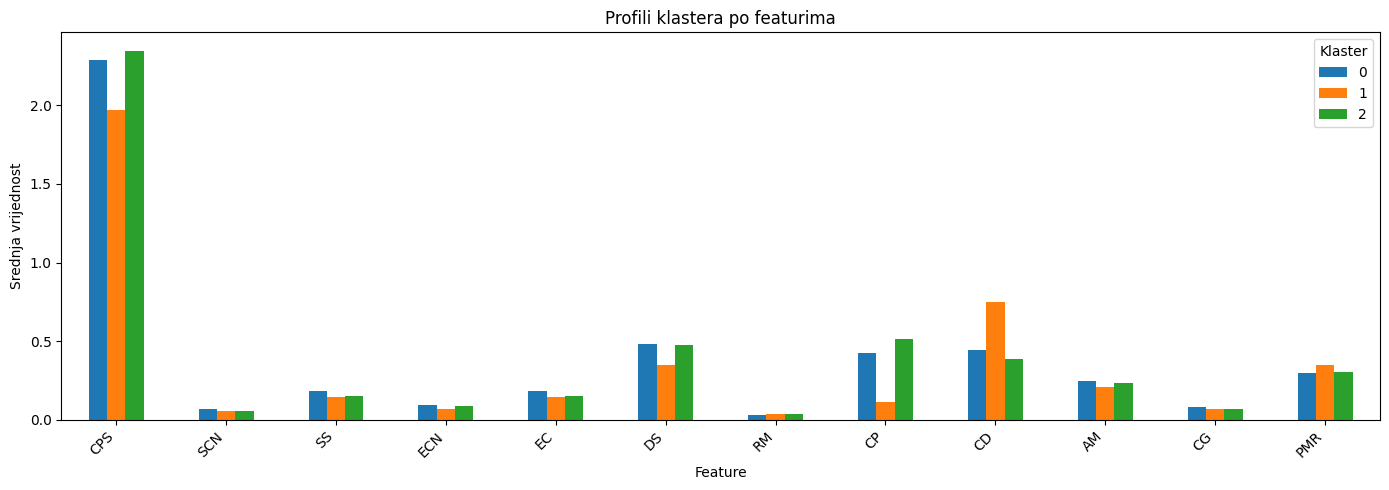

In [15]:
players_feat_vectors = []
players_feat_vectors = load_features() or {
    player: extract_features(games, num_of_moves=10)
    for player, games in player_games.items()
}
X = np.array(list(players_feat_vectors.values()))
features_names = [
    "CPS",
    "SCN",
    "SS",
    "ECN",
    "EC",
    "DS",
    "RM",
    "CP",
    "CD",
    "AM",
    "CG",
    "PMR"
]
evaluation.plot_cluster_profiles(X, labels, features_names)

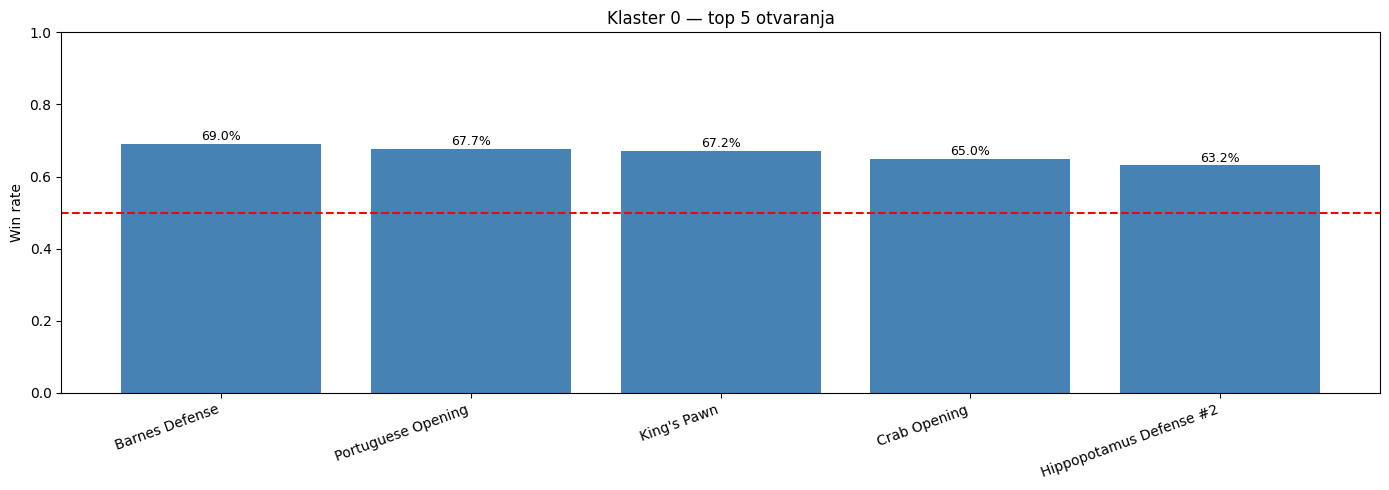

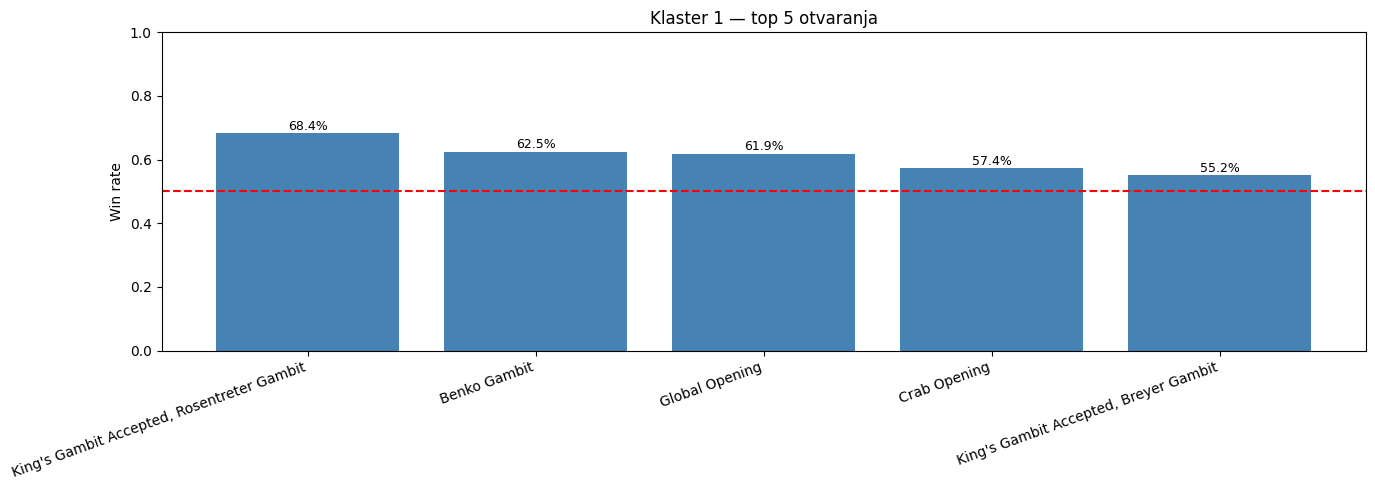

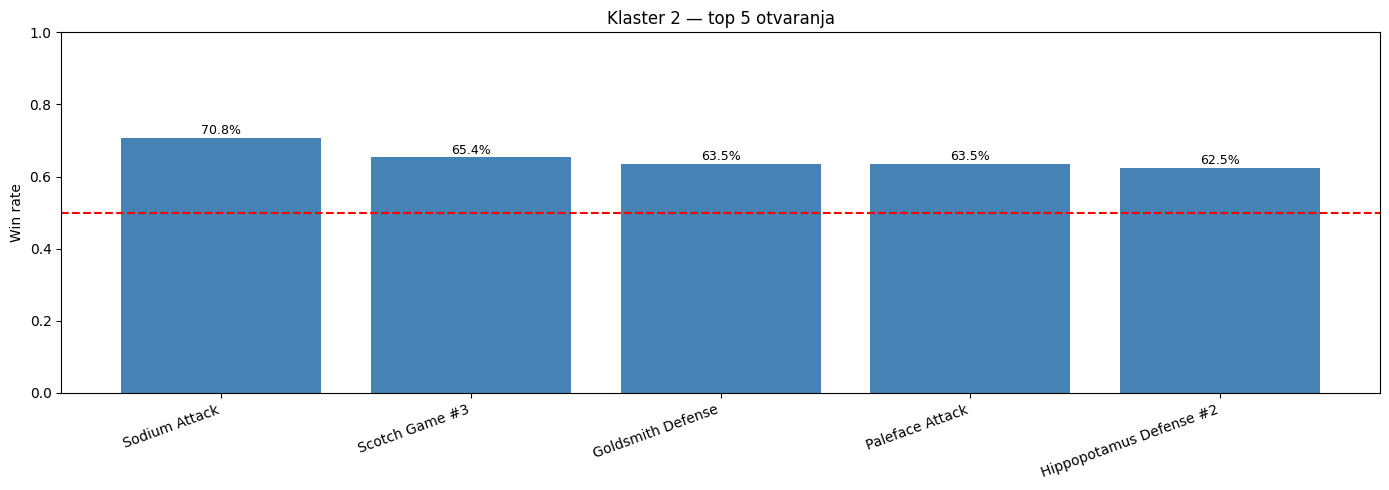

In [16]:
evaluation.plot_top_openings_per_cluster(recommendations)